# Taller Final de Minería de Datos
## Segmentación de clientes con K-Means — *Mall Customers Dataset*

**Objetivo general:** construir un modelo de segmentación de clientes con K-Means, elegir el número de clusters
con el método del codo y el coeficiente de silueta, e interpretar los grupos para apoyar decisiones de marketing.

**Contenido**
1. Exploración de datos
2. Preprocesamiento
3. Método del codo
4. Coeficiente de silueta
5. Modelo K-Means
6. Interpretación de negocio
7. Exportación del modelo para el despliegue con Streamlit

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples, silhouette_score)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEMILLA = 42

# Paleta Calm: Sage, Moss, Mist, Ivory y Sand
SAGE, MOSS, MIST, IVORY, SAND = "#6B7F6E", "#A7B8A7", "#D9E1D9", "#F4EFE8", "#C9BDAF"
SUPERFICIE, TINTA, TINTA_2, TENUE, REJILLA, EJE = "#FBF9F5", "#1F2A22", "#5C6660", "#8A918B", "#E6E0D6", SAND
PRINCIPAL, ACENTO = SAGE, "#815200"

# Tipografía Inter (incluida en fuentes/ con licencia OFL)
from matplotlib import font_manager
if Path("fuentes/Inter.ttf").exists():
    font_manager.fontManager.addfont("fuentes/Inter.ttf")
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TENUE, "ytick.color": TENUE, "text.color": TINTA,
    "legend.frameon": False, "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "DejaVu Sans", "Arial"],
})
pd.set_option("display.float_format", "{:.2f}".format)

Path("figuras").mkdir(exist_ok=True)

def mostrar(nombre):
    # Ajusta, guarda la figura en figuras/ (para el informe) y la muestra
    plt.tight_layout()
    plt.savefig(f"figuras/{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

---
# Parte 1 – Exploración de datos
### 1.1 Cargar el dataset

In [2]:
df = pd.read_csv("Mall_Customers.csv")
df = df.rename(columns={
    "CustomerID": "ID", "Gender": "Genero", "Age": "Edad",
    "Annual Income (k$)": "Ingreso", "Spending Score (1-100)": "Gasto",
})
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones: 200 filas x 5 columnas


,ID,Genero,Edad,Ingreso,Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
print("\nValores nulos por columna:")
print(df.isna().sum())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   ID       200 non-null    int64
 1   Genero   200 non-null    str  
 2   Edad     200 non-null    int64
 3   Ingreso  200 non-null    int64
 4   Gasto    200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Valores nulos por columna:
ID         0
Genero     0
Edad       0
Ingreso    0
Gasto      0
dtype: int64

Filas duplicadas: 0


### 1.2 Identificar variables relevantes

| Variable | Tipo | Descripción | ¿Útil para segmentar? |
|---|---|---|---|
| `ID` | Identificador | Número consecutivo del cliente | **No**: no aporta información de comportamiento |
| `Genero` | Categórica (Male/Female) | Género del cliente | Poco: es binaria y K-Means trabaja con distancias euclidianas |
| `Edad` | Numérica (años) | Edad del cliente | Sí, como variable de perfil |
| `Ingreso` | Numérica (miles de USD/año) | Ingreso anual | **Sí**: capacidad de compra |
| `Gasto` | Numérica (1–100) | Puntaje asignado por el centro comercial según el comportamiento de compra | **Sí**: comportamiento de consumo |

El dataset está limpio: no tiene valores nulos ni filas duplicadas.

### 1.3 Análisis descriptivo básico

In [4]:
num = ["Edad", "Ingreso", "Gasto"]
desc = df[num].describe().T
desc["CV (%)"] = desc["std"] / desc["mean"] * 100
desc

,count,mean,std,min,25%,50%,75%,max,CV (%)
Edad,200.00,38.85,13.97,18.00,28.75,36.00,49.00,70.00,35.96
Ingreso,200.00,60.56,26.26,15.00,41.50,61.50,78.00,137.00,43.37
Gasto,200.00,50.20,25.82,1.00,34.75,50.00,73.00,99.00,51.44


In [5]:
conteo = df["Genero"].value_counts()
print(conteo.to_string(), f"\n\nMujeres: {conteo['Female'] / len(df):.1%}")
df.groupby("Genero")[num].mean()

Genero
Female    112
Male       88 

Mujeres: 56.0%


,Edad,Ingreso,Gasto
Genero,,,
Female,38.10,59.25,51.53
Male,39.81,62.23,48.51


findfont: Failed to find font weight bold for Inter, now using 400.


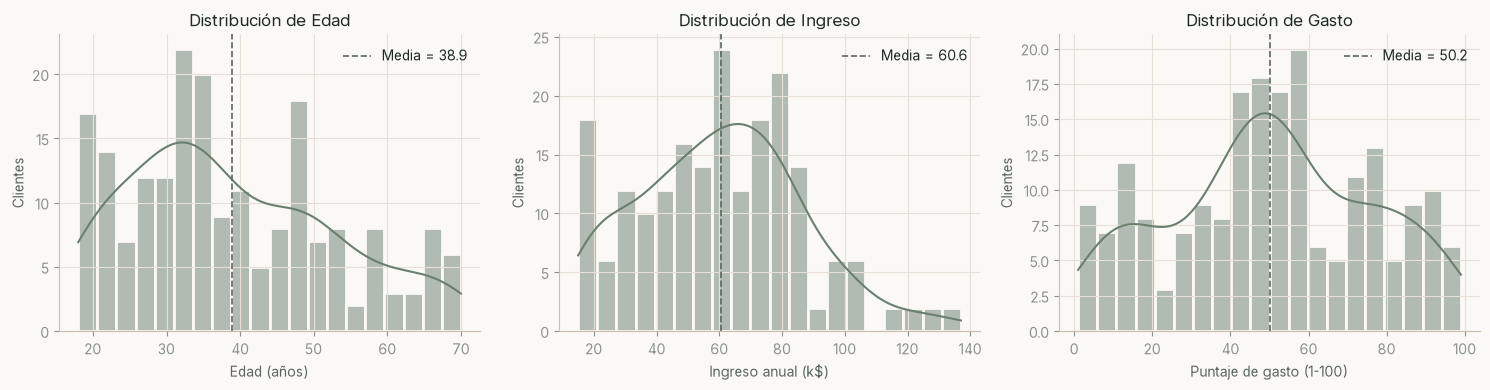

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
NOMBRES = {"Edad": "Edad (años)", "Ingreso": "Ingreso anual (k$)", "Gasto": "Puntaje de gasto (1-100)"}
for ax, col in zip(axes, num):
    sns.histplot(df[col], bins=20, kde=True, color=PRINCIPAL, edgecolor=SUPERFICIE, linewidth=2, ax=ax)
    ax.axvline(df[col].mean(), color=TINTA_2, ls="--", lw=1.2, label=f"Media = {df[col].mean():.1f}")
    ax.set_title(f"Distribución de {col}")
    ax.set_xlabel(NOMBRES[col]); ax.set_ylabel("Clientes")
    ax.legend()
mostrar("01_histogramas")

**Interpretación – Distribuciones**
- **Edad:** asimetría positiva leve (0.49). Hay más clientes jóvenes: la mayoría tiene entre 18 y 50 años y pocos
  pasan de 60. La media (38.9) es mayor que la mediana (36), señal de una cola hacia edades mayores.
- **Ingreso:** casi simétrico alrededor de 60 k$ (mediana 61.5), con una cola derecha corta (asimetría 0.32). Por
  encima de 100 k$ hay muy pocos clientes, y los valores más altos son dos registros de 137 k$.
- **Gasto:** simétrico (asimetría −0.05) y centrado en 50, pero **plano** (curtosis −0.83). Tiene un pico en 40–60 y
  colas con muchos clientes, en vez de una campana. Esto sugiere una mezcla de grupos con distinto nivel de gasto.

Ninguna variable tiene un sesgo fuerte que obligue a transformarla (por ejemplo, con logaritmo). La estandarización es
suficiente.

#### Detección de valores atípicos (criterio IQR de Tukey)

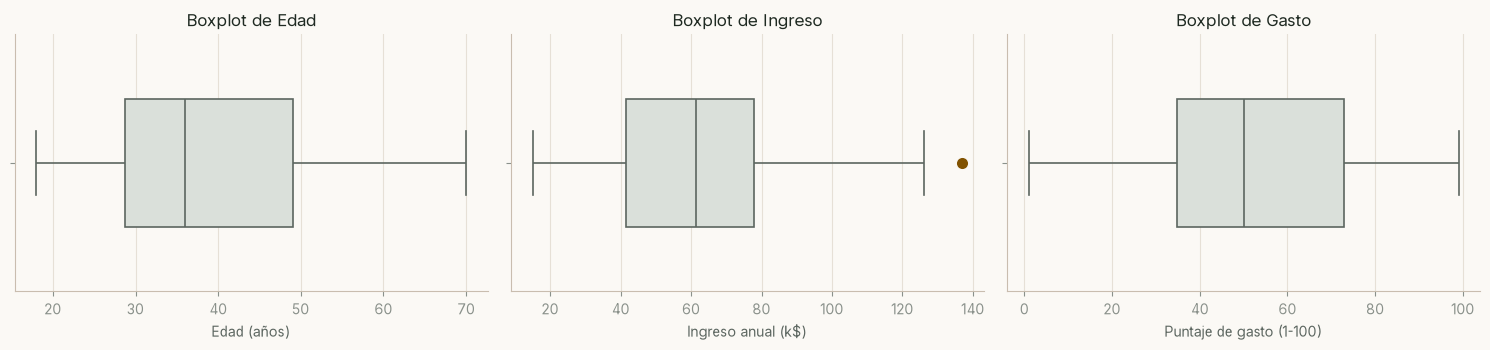

,Variable,Límite inferior,Límite superior,N° atípicos,Valores
0,Edad,-1.62,79.38,0,[]
1,Ingreso,-13.25,132.75,2,"[137, 137]"
2,Gasto,-22.62,130.38,0,[]


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, num):
    sns.boxplot(x=df[col], color=MIST, linecolor=TINTA_2, linewidth=1.2, width=0.5,
                flierprops={"marker": "o", "markerfacecolor": ACENTO, "markeredgecolor": SUPERFICIE,
                            "markersize": 9}, ax=ax)
    ax.set_title(f"Boxplot de {col}"); ax.set_xlabel(NOMBRES[col])
mostrar("02_boxplots")

filas = []
for col in num:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = df[(df[col] < li) | (df[col] > ls)]
    filas.append({"Variable": col, "Límite inferior": li, "Límite superior": ls,
                  "N° atípicos": len(atipicos), "Valores": atipicos[col].tolist()})
pd.DataFrame(filas)

**Interpretación – Boxplots**
- **Edad** y **Gasto** no tienen puntos fuera de los bigotes, es decir, no hay valores atípicos.
- **Ingreso** tiene un punto aislado a la derecha (en realidad son **dos clientes con 137 k$**). Es el único atípico
  del dataset.
- **Gasto** tiene la caja más ancha (IQR = 38.25) y el mayor coeficiente de variación (51 %). Es la variable más
  heterogénea y la que más ayuda a diferenciar clientes.
- La mediana de cada variable está casi en el centro de su caja, lo que confirma distribuciones sin asimetría fuerte.

#### Relaciones entre variables

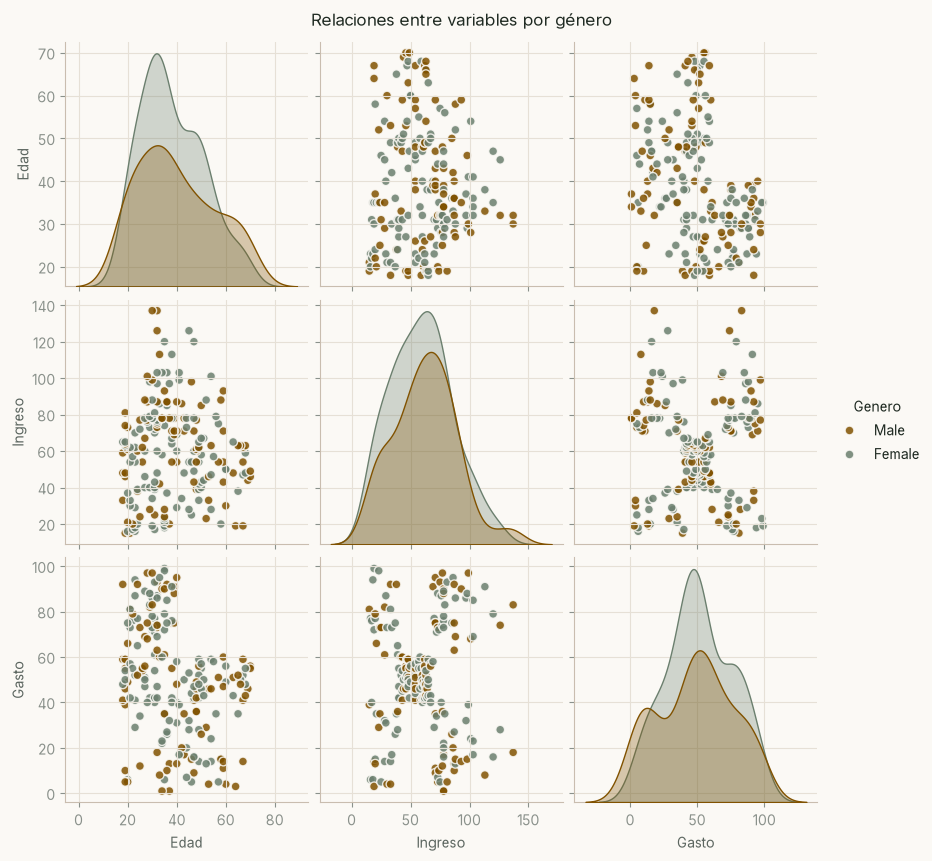

In [8]:
g = sns.pairplot(df, vars=num, hue="Genero", palette={"Female": PRINCIPAL, "Male": ACENTO},
                 plot_kws={"s": 40, "edgecolor": SUPERFICIE, "linewidth": 1, "alpha": 0.85},
                 diag_kws={"fill": True, "alpha": 0.3}, height=2.8)
g.figure.suptitle("Relaciones entre variables por género", y=1.02, fontweight="bold")
plt.savefig("figuras/03_pairplot.png", dpi=200, bbox_inches="tight")
plt.show()

**Interpretación – Diagrama de pares**
- **Ingreso vs. Gasto** (fila 3, columna 2): es el panel más revelador. Los puntos forman **cinco nubes**: una en el
  centro y cuatro en las esquinas. Esta es la estructura natural que va a encontrar K-Means.
- **Edad vs. Gasto:** los puntos forman un **triángulo**. Los gastos altos solo aparecen en edades bajas: **los 62
  clientes con gasto mayor a 60 tienen 40 años o menos**, y ningún mayor de 40 supera ese puntaje.
- **Edad vs. Ingreso:** nube sin forma definida, sin relación.
- **Género:** los puntos verde salvia (mujeres) y ocre (hombres) están mezclados en todos los paneles, y sus curvas de
  densidad en la diagonal casi se superponen. El género no separa grupos.

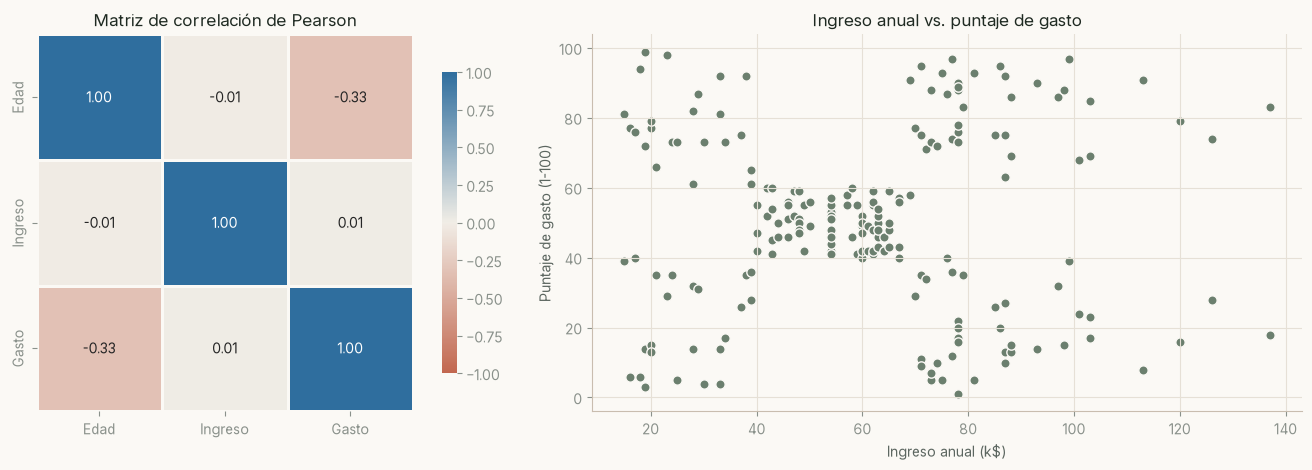

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
corr = df[num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.blend_palette(["#C2674F", "#F1EDE6", "#2F6E9E"], as_cmap=True),
            vmin=-1, vmax=1, square=True, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"shrink": 0.8}, ax=axes[0])
axes[0].set_title("Matriz de correlación de Pearson"); axes[0].grid(False)

axes[1].scatter(df["Ingreso"], df["Gasto"], s=45, color=PRINCIPAL, edgecolor=SUPERFICIE, linewidth=1)
axes[1].set_title("Ingreso anual vs. puntaje de gasto")
axes[1].set_xlabel("Ingreso anual (k$)"); axes[1].set_ylabel("Puntaje de gasto (1-100)")
mostrar("04_correlacion_dispersion")

**Interpretación – Correlaciones y dispersión**
- La única correlación que importa es **Edad–Gasto (r = −0.33)**: negativa y moderada. Los clientes de 40 años o
  menos tienen un gasto medio de 59.3, frente a 36.0 de los mayores de 40.
- **Ingreso–Gasto tiene r = 0.01**, pero el diagrama de la derecha muestra que **sí hay estructura**: cinco grupos
  bien definidos. La correlación de Pearson solo mide relaciones **lineales**, y aquí la relación es por grupos.
  Por eso este problema se resuelve con *clustering* y no con regresión.
- Que las dos variables de segmentación no estén correlacionadas es una ventaja: cada una aporta información distinta
  y no hay redundancia.

### Preguntas – Parte 1

**¿Qué variables son más adecuadas para segmentar clientes?**

**Ingreso anual** y **puntaje de gasto**. Las dos describen directamente el valor económico del cliente: cuánto
*puede* gastar y cuánto *gasta*. Además:
- No están correlacionadas entre sí (r ≈ 0.01), así que cada una aporta información distinta.
- En el diagrama de dispersión Ingreso vs. Gasto se ven a simple vista **cinco nubes de puntos** separadas: una
  central y cuatro en las esquinas. Esa estructura es justo la que K-Means detecta bien.
- Son fáciles de interpretar para el área de marketing.

La **edad** sirve para *describir* los segmentos (tiene una correlación de −0.33 con el gasto), pero en la Parte 4
se comprueba que agregarla al modelo baja la calidad de los clusters. El **género** no se usa: las medias de
edad, ingreso y gasto casi no cambian entre hombres y mujeres, y por ser binaria distorsiona la distancia euclidiana.
El **ID** es solo un identificador.

**¿Se identifican valores atípicos?**

Con el criterio IQR (1.5 × rango intercuartílico) solo aparecen **2 valores atípicos**, ambos en `Ingreso`
(137 k$, por encima del límite superior de 132.75 k$). `Edad` y `Gasto` no tienen atípicos. Se decide **conservarlos**
porque:
1. Son valores posibles (clientes de muy alto ingreso), no errores de digitación.
2. Apenas superan el límite (137 vs. 132.75).
3. Son el 1 % de los datos y, al estandarizar, quedan a unas 2.9 desviaciones de la media: no arrastran ningún centroide.

**¿Qué tipo de relaciones se observan entre las variables?**

- **Ingreso – Gasto:** no hay relación lineal (r = 0.01). Que alguien gane más no significa que gaste más. Lo que
  sí se ve es una relación **no lineal por grupos**: cinco agrupaciones claras. Por eso el problema se resuelve
  mejor con *clustering* que con regresión.
- **Edad – Gasto:** relación **negativa moderada** (r = −0.33). Los 62 clientes con gasto mayor a 60 tienen 40 años
  o menos, y ningún mayor de 40 supera ese puntaje. El gasto medio es 59.3 en los menores de 41 y 36.0 en los mayores.
- **Edad – Ingreso:** sin relación (r = −0.01).
- **Género:** las distribuciones de hombres y mujeres se superponen casi por completo, así que no separa grupos.

---
# Parte 2 – Preprocesamiento
Se seleccionan las variables de segmentación y se estandarizan con `StandardScaler`:
$z = \dfrac{x - \mu}{\sigma}$, de modo que cada variable queda con media 0 y desviación estándar 1.

In [10]:
FEATURES = ["Ingreso", "Gasto"]
X = df[FEATURES].values

scaler = StandardScaler()
X_esc = scaler.fit_transform(X)

resumen = pd.DataFrame({
    "Media original": X.mean(axis=0), "Desv. original": X.std(axis=0),
    "Media escalada": X_esc.mean(axis=0).round(6), "Desv. escalada": X_esc.std(axis=0),
}, index=FEATURES)
resumen

,Media original,Desv. original,Media escalada,Desv. escalada
Ingreso,60.56,26.20,-0.00,1.00
Gasto,50.20,25.76,-0.00,1.00


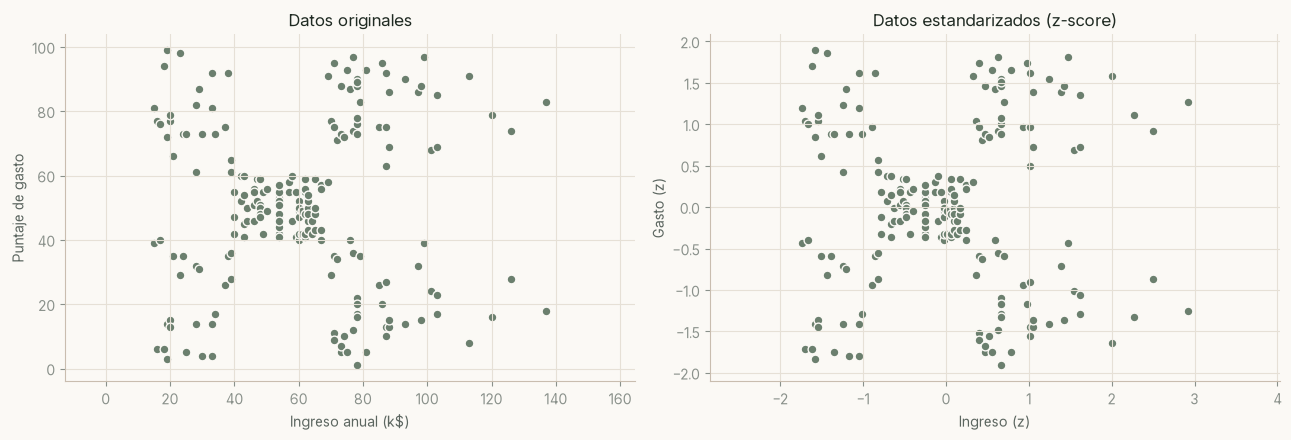

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(X[:, 0], X[:, 1], s=40, color=PRINCIPAL, edgecolor=SUPERFICIE, linewidth=1)
axes[0].set_title("Datos originales"); axes[0].set_xlabel("Ingreso anual (k$)"); axes[0].set_ylabel("Puntaje de gasto")
axes[1].scatter(X_esc[:, 0], X_esc[:, 1], s=40, color=PRINCIPAL, edgecolor=SUPERFICIE, linewidth=1)
axes[1].set_title("Datos estandarizados (z-score)"); axes[1].set_xlabel("Ingreso (z)"); axes[1].set_ylabel("Gasto (z)")
for ax in axes:
    ax.set_aspect("equal", adjustable="datalim")
mostrar("05_escalado")

**Interpretación – Efecto del escalado**
Las dos nubes tienen **exactamente la misma forma**: la estandarización es una transformación lineal, así que solo
mueve el centro a (0, 0) y deja ambas variables con desviación 1, sin cambiar las posiciones relativas de los
clientes ni los grupos. Lo que cambia es que ahora una unidad en el eje X pesa lo mismo que una unidad en el eje Y
dentro de la distancia euclidiana. El cliente de 137 k$ queda en z = 2.92, a menos de tres desviaciones de la media.

### Pregunta – Parte 2

**¿Por qué es necesario escalar las variables en el algoritmo K-Means?**

K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**:
$d = \sqrt{\sum_j (x_j - c_j)^2}$. Esa distancia suma diferencias de todas las variables, así que una variable con
números más grandes o más dispersos **pesa más** en la distancia, aunque no sea más importante.

En este dataset, el ingreso va de 15 a 137 y el gasto de 1 a 99, con desviaciones de 26.2 y 25.7. Aquí las escalas
son parecidas, pero si se agrega la edad (σ ≈ 14) o el ingreso se expresa en dólares y no en miles (σ ≈ 26 000),
el ingreso dominaría toda la segmentación y el gasto prácticamente no contaría.

`StandardScaler` deja todas las variables con media 0 y desviación 1, así que:
1. Cada variable aporta **lo mismo** a la distancia.
2. Los clusters dependen de la forma de los datos y no de las unidades de medida.
3. El algoritmo converge de forma más estable, porque los centroides se mueven en un espacio equilibrado.

El escalador se guarda junto con el modelo: cada cliente nuevo debe transformarse con la **misma** media y desviación
antes de clasificarlo.

---
# Parte 3 – Método del codo
Se entrena K-Means para K = 1, …, 10 y se registra la **inercia** (WCSS, *Within-Cluster Sum of Squares*):
$WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$.
Se usa `n_init=50` (50 inicializaciones k-means++) para no quedarse en un mínimo local.

In [12]:
RANGO_K = range(1, 11)
inercias = [KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit(X_esc).inertia_ for k in RANGO_K]

# Punto de codo: el K más alejado de la recta que une el primer y el último punto (método Kneedle)
p = np.column_stack([list(RANGO_K), inercias]).astype(float)
p_norm = (p - p.min(axis=0)) / (p.max(axis=0) - p.min(axis=0))
recta = p_norm[-1] - p_norm[0]
dif = p_norm[0] - p_norm
dist_recta = np.abs(recta[0] * dif[:, 1] - recta[1] * dif[:, 0]) / np.linalg.norm(recta)
K_CODO = list(RANGO_K)[int(np.argmax(dist_recta))]

tabla_codo = pd.DataFrame({"K": list(RANGO_K), "Inercia (WCSS)": inercias})
tabla_codo["Reducción vs K-1 (%)"] = (-tabla_codo["Inercia (WCSS)"].pct_change() * 100).round(1)
print(f"Codo detectado automáticamente: K = {K_CODO}")
tabla_codo

Codo detectado automáticamente: K = 5


,K,Inercia (WCSS),Reducción vs K-1 (%)
0,1,400.00,NaN
1,2,269.69,32.60
2,3,157.70,41.50
3,4,108.92,30.90
4,5,65.57,39.80
5,6,55.06,16.00
6,7,44.86,18.50
7,8,37.15,17.20
8,9,32.36,12.90
9,10,29.08,10.10


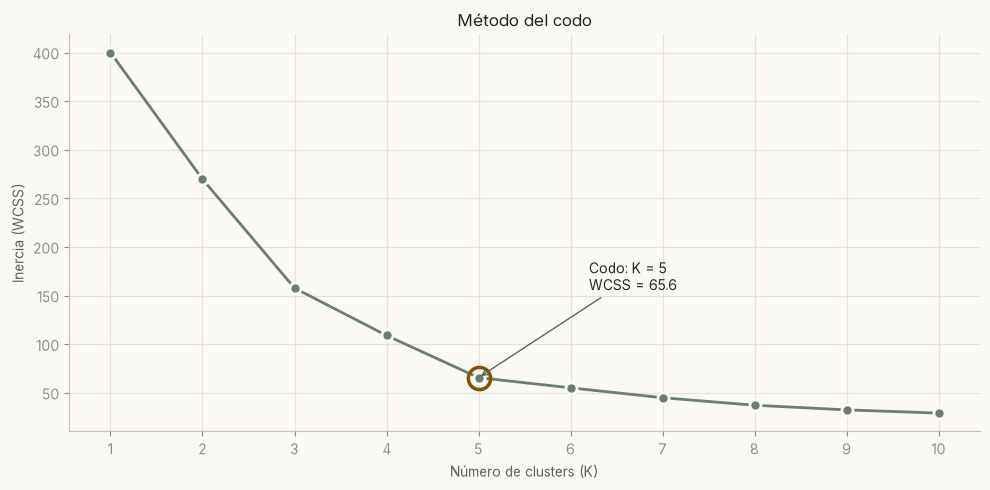

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(list(RANGO_K), inercias, color=PRINCIPAL, lw=2, marker="o", ms=8, mec=SUPERFICIE, mew=2)
ax.plot(K_CODO, inercias[K_CODO - 1], marker="o", ms=16, mfc="none", mec=ACENTO, mew=2.5)
ax.annotate(f"Codo: K = {K_CODO}\nWCSS = {inercias[K_CODO - 1]:.1f}", xy=(K_CODO, inercias[K_CODO - 1]),
            xytext=(K_CODO + 1.2, inercias[K_CODO - 1] + 90), color=TINTA,
            arrowprops={"arrowstyle": "->", "color": TINTA_2})
ax.set_xticks(list(RANGO_K))
ax.set_title("Método del codo"); ax.set_xlabel("Número de clusters (K)"); ax.set_ylabel("Inercia (WCSS)")
mostrar("06_codo")

**Interpretación – Método del codo**
La curva baja con fuerza de K = 1 a K = 5 (de 400 a 65.6, **−84 %**). Desde K = 5 se vuelve casi plana: cada cluster
adicional reduce la inercia apenas entre 10 % y 18 %. El círculo ocre marca el **codo en K = 5**, donde agregar
grupos ya no compensa la complejidad extra. El método automático (punto más alejado de la recta entre los extremos)
llega al mismo valor.

### Preguntas – Parte 3

**¿Por qué valores cercanos a cero indican mejor ajuste?**

La inercia es la **suma de las distancias al cuadrado** de cada cliente a su centroide. Si es cercana a cero, los
clientes de cada cluster están muy cerca de su centroide: los grupos son **compactos y homogéneos** y el centroide
representa bien a sus miembros. Una inercia alta indica clusters dispersos, con clientes muy distintos dentro del
mismo grupo.

Ojo: la inercia **siempre baja** al aumentar K, y llega a 0 cuando K = n (cada cliente es su propio cluster). Ese
modelo tiene un "ajuste perfecto", pero no sirve: es sobreajuste y no resume nada. Por eso no se elige el K con la
menor inercia, sino el K a partir del cual agregar clusters **ya no reduce la inercia de forma importante**.

**¿Cómo se identifica el punto óptimo de K?**

Se busca el **codo** de la curva: el punto donde la pendiente cambia de fuerte a suave.
- De K = 1 a K = 5 la inercia cae de 400 a 65.6 (**−84 %** en total). El paso de 4 a 5 todavía reduce un **39.8 %**.
- Desde K = 6 cada cluster nuevo reduce la inercia mucho menos (16 %, 18 %, 17 %, 13 %…) y la curva se aplana.
- El cálculo automático (el punto más alejado de la recta que une los extremos de la curva) confirma **K = 5**.

Conclusión del método del codo: **K = 5**.

---
# Parte 4 – Coeficiente de silueta
Para cada cliente *i*: $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$, donde $a(i)$ es la distancia promedio a
los clientes de **su** cluster y $b(i)$ la distancia promedio al cluster **vecino más cercano**. Junto a la silueta
se calculan otras dos métricas internas como respaldo:
- **Davies-Bouldin** (menor es mejor).
- **Calinski-Harabasz** (mayor es mejor).

In [14]:
def evaluar(Xm, ks=range(2, 11)):
    filas = []
    for k in ks:
        etiquetas = KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit_predict(Xm)
        filas.append({"K": k, "Silueta": silhouette_score(Xm, etiquetas),
                      "Davies-Bouldin": davies_bouldin_score(Xm, etiquetas),
                      "Calinski-Harabasz": calinski_harabasz_score(Xm, etiquetas)})
    return pd.DataFrame(filas)

metricas = evaluar(X_esc)
K_SILUETA = int(metricas.loc[metricas["Silueta"].idxmax(), "K"])
print(f"Mejor K según silueta: {K_SILUETA}  (s = {metricas['Silueta'].max():.4f})")
metricas.style.format({"Silueta": "{:.4f}", "Davies-Bouldin": "{:.3f}", "Calinski-Harabasz": "{:.1f}"}) \
    .highlight_max(subset=["Silueta", "Calinski-Harabasz"], color=MIST) \
    .highlight_min(subset=["Davies-Bouldin"], color=MIST)

Mejor K según silueta: 5  (s = 0.5547)


,K,Silueta,Davies-Bouldin,Calinski-Harabasz
0,2,0.3213,1.267,95.7
1,3,0.4666,0.716,151.3
2,4,0.4939,0.710,174.6
3,5,0.5547,0.572,248.6
4,6,0.5399,0.655,243.1
5,7,0.5281,0.715,254.6
6,8,0.4567,0.758,267.9
7,9,0.4565,0.754,271.2
8,10,0.4494,0.755,269.3


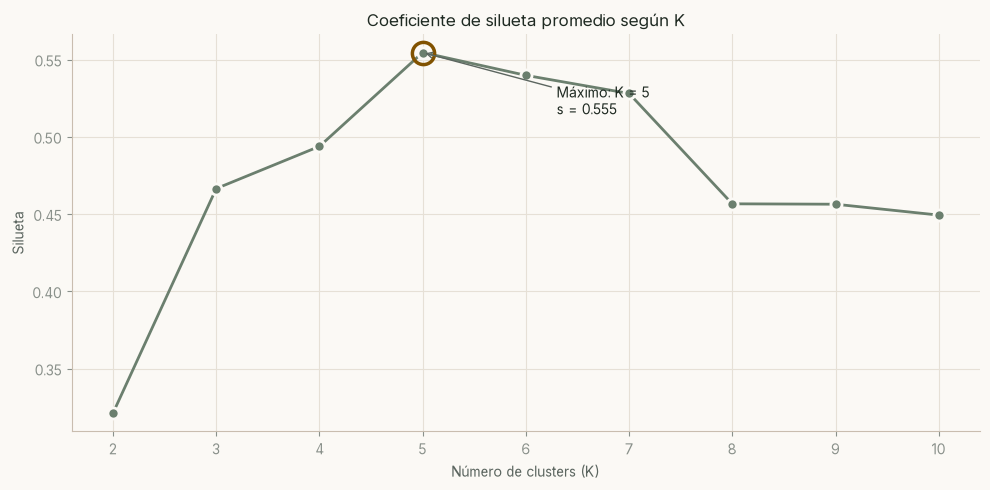

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(metricas["K"], metricas["Silueta"], color=PRINCIPAL, lw=2, marker="o", ms=8, mec=SUPERFICIE, mew=2)
s_max = metricas["Silueta"].max()
ax.plot(K_SILUETA, s_max, marker="o", ms=16, mfc="none", mec=ACENTO, mew=2.5)
ax.annotate(f"Máximo: K = {K_SILUETA}\ns = {s_max:.3f}", xy=(K_SILUETA, s_max),
            xytext=(K_SILUETA + 1.3, s_max - 0.04), color=TINTA,
            arrowprops={"arrowstyle": "->", "color": TINTA_2})
ax.set_xticks(metricas["K"])
ax.set_title("Coeficiente de silueta promedio según K"); ax.set_xlabel("Número de clusters (K)"); ax.set_ylabel("Silueta")
mostrar("07_silueta")

**Interpretación – Silueta promedio**
La silueta sube de 0.321 (K = 2) hasta su **máximo de 0.555 en K = 5**, baja un poco en K = 6 (0.540) y K = 7 (0.528)
y cae con fuerza desde K = 8 (0.457). El pico es claro y coincide con el codo. Un valor de 0.555 está en el rango
de **estructura razonable** (0.51–0.70) de Kaufman y Rousseeuw.

#### Diagrama de silueta por cliente (K = 3, 5 y 7)
Cada barra horizontal es un cliente. Sirve para ver si **todos** los clusters son buenos o si el promedio esconde
grupos débiles o clientes mal asignados (barras negativas).

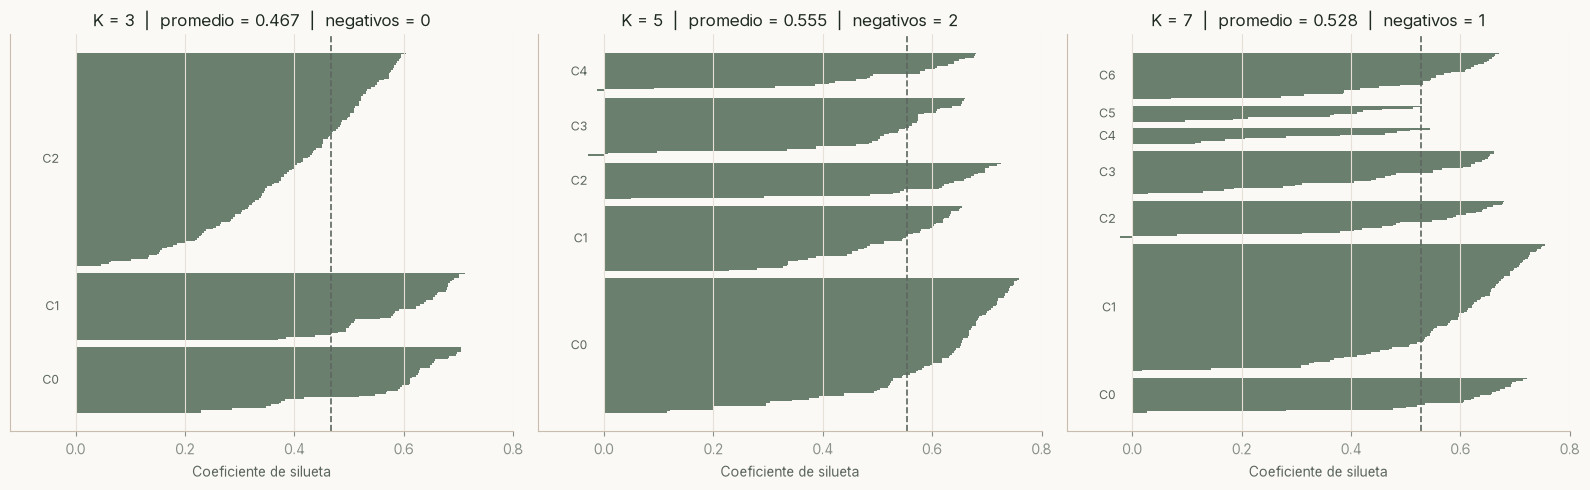

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, k in zip(axes, [3, 5, 7]):
    etiquetas = KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit_predict(X_esc)
    s_i = silhouette_samples(X_esc, etiquetas)
    y = 0
    for c in range(k):
        v = np.sort(s_i[etiquetas == c])
        ax.barh(np.arange(y, y + len(v)), v, height=1.0, color=PRINCIPAL, edgecolor="none")
        ax.text(-0.03, y + len(v) / 2, f"C{c}", ha="right", va="center", color=TINTA_2, fontsize=9)
        y += len(v) + 4
    ax.axvline(s_i.mean(), color=TINTA_2, ls="--", lw=1.2)
    ax.set_title(f"K = {k}  |  promedio = {s_i.mean():.3f}  |  negativos = {(s_i < 0).sum()}")
    ax.set_xlabel("Coeficiente de silueta"); ax.set_yticks([]); ax.grid(axis="y", visible=False)
    ax.set_xlim(-0.12, 0.8)
mostrar("08_diagrama_silueta")

**Interpretación – Diagrama de silueta por cliente**
- **K = 5:** los cinco grupos tienen bandas de grosor proporcional y siluetas medias de 0.505 a 0.598. Entre el
  **85 % y el 91 % de los clientes de cada grupo supera 0.35**. Solo **2 de 200** tienen silueta negativa (−0.012 y
  −0.029): los clientes (39 k$, 36) y (77 k$, 36), que están en la frontera con el grupo promedio.
- **K = 3:** el grupo C2 reúne **123 clientes** porque mezcla los grupos promedio, impulsivos y bajo valor. Por eso su
  banda es muy grande y con muchos valores cercanos a 0 (silueta media 0.397).
- **K = 7:** los grupos de alto valor y con potencial se parten según el ingreso, y aparecen dos grupos de **solo 10
  clientes** con más de 100 k$ (C4 y C5). Sus siluetas son las más bajas (0.33 y 0.36): es una división artificial.

#### ¿Y si se agrega la edad? Comparación de conjuntos de variables
Se prueba también la segmentación con **Edad + Ingreso + Gasto** para justificar la elección de variables.

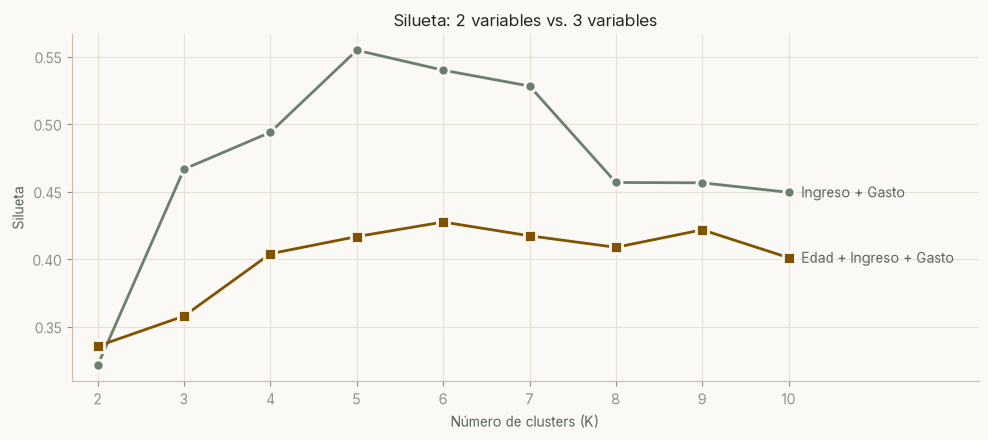

,Variables,Mejor K (silueta),Silueta máxima,Davies-Bouldin mínimo
0,Ingreso + Gasto,5,0.55,0.57
1,Edad + Ingreso + Gasto,6,0.43,0.79


In [17]:
X3_esc = StandardScaler().fit_transform(df[["Edad", "Ingreso", "Gasto"]])
metricas_3 = evaluar(X3_esc)

comparacion = pd.DataFrame({
    "Variables": ["Ingreso + Gasto", "Edad + Ingreso + Gasto"],
    "Mejor K (silueta)": [K_SILUETA, int(metricas_3.loc[metricas_3["Silueta"].idxmax(), "K"])],
    "Silueta máxima": [metricas["Silueta"].max(), metricas_3["Silueta"].max()],
    "Davies-Bouldin mínimo": [metricas["Davies-Bouldin"].min(), metricas_3["Davies-Bouldin"].min()],
})

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(metricas["K"], metricas["Silueta"], color=PRINCIPAL, lw=2, marker="o", ms=8, mec=SUPERFICIE, mew=2)
ax.plot(metricas_3["K"], metricas_3["Silueta"], color=ACENTO, lw=2, marker="s", ms=8, mec=SUPERFICIE, mew=2)
ax.text(10.15, metricas["Silueta"].iloc[-1], "Ingreso + Gasto", color=TINTA_2, va="center")
ax.text(10.15, metricas_3["Silueta"].iloc[-1], "Edad + Ingreso + Gasto", color=TINTA_2, va="center")
ax.set_xlim(1.7, 12.2); ax.set_xticks(metricas["K"])
ax.set_title("Silueta: 2 variables vs. 3 variables"); ax.set_xlabel("Número de clusters (K)"); ax.set_ylabel("Silueta")
mostrar("09_comparacion_variables")
comparacion

**Interpretación – 2 variables vs. 3 variables**
Desde K = 3, la curva verde salvia (Ingreso + Gasto) está **siempre por encima** de la ocre (Edad + Ingreso + Gasto). Solo
en K = 2 la versión con edad es un poco mejor (0.335 vs. 0.321). El mejor resultado con edad (0.427) está muy lejos
de 0.555. La edad agrega una dimensión sin grupos claros que mezcla los segmentos, así que se deja fuera del
entrenamiento y se usa solo para describir los perfiles.

### Preguntas – Parte 4

**¿Qué mide el coeficiente de silueta?**

Mide qué tan bien asignado está cada cliente a su cluster comparando dos cosas:
- **Cohesión** $a(i)$: qué tan cerca está de los clientes de su propio grupo.
- **Separación** $b(i)$: qué tan lejos está del grupo vecino más cercano.

Su valor va de −1 a 1. El promedio de todos los clientes resume la calidad del clustering completo. A diferencia de
la inercia, la silueta **no mejora sola al aumentar K**, así que sirve para comparar distintos valores de K.

**¿Qué significa un valor cercano a 1?**

Que $a(i) \ll b(i)$: el cliente está muy cerca de los de su grupo y lejos de los demás. Los clusters son
**compactos y bien separados**, y la asignación es clara. Como referencia (Kaufman & Rousseeuw): > 0.70 es una
estructura fuerte, 0.51–0.70 razonable, 0.26–0.50 débil y < 0.25 sin estructura importante.

**¿Qué implica un valor cercano a 0 o negativo?**

- **Cercano a 0:** el cliente está en la **frontera** entre dos clusters ($a(i) \approx b(i)$) y podría estar en
  cualquiera de los dos. Si el promedio es cercano a 0, los grupos se superponen.
- **Negativo:** el cliente está más cerca de **otro** cluster que del suyo ($a(i) > b(i)$), es decir, está **mal
  asignado**. Muchos valores negativos indican que el K elegido o las variables no son adecuados.

**¿Coincide el valor óptimo de K con el método del codo? Justifique.**

**Sí, coinciden en K = 5.**
- **Codo:** la inercia deja de bajar con fuerza después de K = 5 (de 65.6 a 55.1 con K = 6).
- **Silueta:** el máximo es **0.555 en K = 5**, una estructura *razonable* según la escala anterior. K = 6 (0.540) y
  K = 7 (0.528) son peores.
- **Davies-Bouldin:** su mínimo también está en K = 5 (0.572).
- En el diagrama de silueta con K = 5, entre el 85 % y el 91 % de los clientes de cada grupo supera 0.35, y solo
  **2 de 200** tienen silueta negativa (clientes en la frontera con el grupo promedio). Con K = 3, un grupo de 123
  clientes mezcla tres nubes distintas (silueta 0.397). Con K = 7, los clientes de ingreso alto se parten en
  grupos de solo 10 clientes con silueta baja (0.33 y 0.36).

Que métodos distintos (uno basado en compacidad y otro en compacidad + separación) lleguen al mismo K da
**confianza** en la elección. Además, K = 5 coincide con las cinco nubes que se veían en el diagrama de dispersión
de la Parte 1.

**Sobre las variables:** con Edad + Ingreso + Gasto la mejor silueta es solo **0.427** (K = 6) y el Davies-Bouldin
empeora. Agregar la edad mezcla los grupos, así que el modelo final usa **Ingreso + Gasto con K = 5** y la edad se
usa después para describir cada segmento.

---
# Parte 5 – Modelo K-Means
### Entrenamiento con K = 5, asignación de clusters y centroides

In [18]:
K = 5
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=50, max_iter=500, random_state=SEMILLA)
df["Cluster"] = kmeans.fit_predict(X_esc)

print(f"Iteraciones hasta converger: {kmeans.n_iter_}")
print(f"Inercia final: {kmeans.inertia_:.2f}")
print(f"Silueta: {silhouette_score(X_esc, df['Cluster']):.4f}")
print(f"Davies-Bouldin: {davies_bouldin_score(X_esc, df['Cluster']):.4f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_esc, df['Cluster']):.1f}")

Iteraciones hasta converger: 4
Inercia final: 65.57
Silueta: 0.5547
Davies-Bouldin: 0.5722
Calinski-Harabasz: 248.6


**Estabilidad del modelo:** K-Means depende de la inicialización. Se entrena 20 veces con semillas distintas y se
compara cada resultado con el modelo final usando el *Adjusted Rand Index* (ARI = 1 significa que los grupos son
idénticos).

In [19]:
ari = [adjusted_rand_score(df["Cluster"], KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X_esc))
       for s in range(20)]
print(f"ARI promedio en 20 semillas: {np.mean(ari):.4f}  (mínimo {np.min(ari):.4f})")

ARI promedio en 20 semillas: 1.0000  (mínimo 1.0000)


In [20]:
# Centroides en escala estandarizada y en unidades originales
centroides_esc = kmeans.cluster_centers_
centroides = pd.DataFrame(scaler.inverse_transform(centroides_esc), columns=FEATURES)
centroides.index.name = "Cluster"
centroides[["Ingreso (z)", "Gasto (z)"]] = centroides_esc
centroides

,Ingreso,Gasto,Ingreso (z),Gasto (z)
Cluster,,,,
0,55.30,49.52,-0.20,-0.03
1,86.54,82.13,0.99,1.24
2,25.73,79.36,-1.33,1.13
3,88.20,17.11,1.06,-1.28
4,26.30,20.91,-1.31,-1.14


### Asignación de perfiles de negocio
Para que el nombre de cada cluster **no dependa del número que le asigne K-Means** (que puede cambiar entre
ejecuciones), el perfil se asigna con una regla sobre la posición del centroide en la escala estandarizada:
- El centroide más cercano al origen (0, 0) corresponde a los clientes **promedio**.
- Los demás se nombran según el signo de su ingreso y gasto respecto a la media.

In [21]:
PERFILES = {
    "alto":      {"nombre": "Clientes de alto valor",  "color": "#3e8651", "marcador": "o"},
    "potencial": {"nombre": "Clientes con potencial",  "color": "#815200", "marcador": "s"},
    "promedio":  {"nombre": "Clientes promedio",       "color": "#4494c8", "marcador": "D"},
    "impulsivo": {"nombre": "Clientes impulsivos",     "color": "#e08b75", "marcador": "^"},
    "bajo":      {"nombre": "Clientes de bajo valor",  "color": "#985b93", "marcador": "v"},
}

def asignar_perfiles(centros_esc):
    centro_promedio = int(np.argmin(np.linalg.norm(centros_esc, axis=1)))
    mapa = {}
    for c, (ing, gas) in enumerate(centros_esc):
        if c == centro_promedio:
            mapa[c] = "promedio"
        elif ing >= 0:
            mapa[c] = "alto" if gas >= 0 else "potencial"
        else:
            mapa[c] = "impulsivo" if gas >= 0 else "bajo"
    return mapa

MAPA_PERFIL = asignar_perfiles(centroides_esc)
assert len(set(MAPA_PERFIL.values())) == K, "Cada cluster debe tener un perfil distinto"
df["Perfil"] = df["Cluster"].map(lambda c: PERFILES[MAPA_PERFIL[c]]["nombre"])
ORDEN = [PERFILES[p]["nombre"] for p in PERFILES]
centroides["Perfil"] = [PERFILES[MAPA_PERFIL[c]]["nombre"] for c in centroides.index]
centroides

,Ingreso,Gasto,Ingreso (z),Gasto (z),Perfil
Cluster,,,,,
0,55.30,49.52,-0.20,-0.03,Clientes promedio
1,86.54,82.13,0.99,1.24,Clientes de alto valor
2,25.73,79.36,-1.33,1.13,Clientes impulsivos
3,88.20,17.11,1.06,-1.28,Clientes con potencial
4,26.30,20.91,-1.31,-1.14,Clientes de bajo valor


findfont: Failed to find font weight bold for Inter, now using 400.


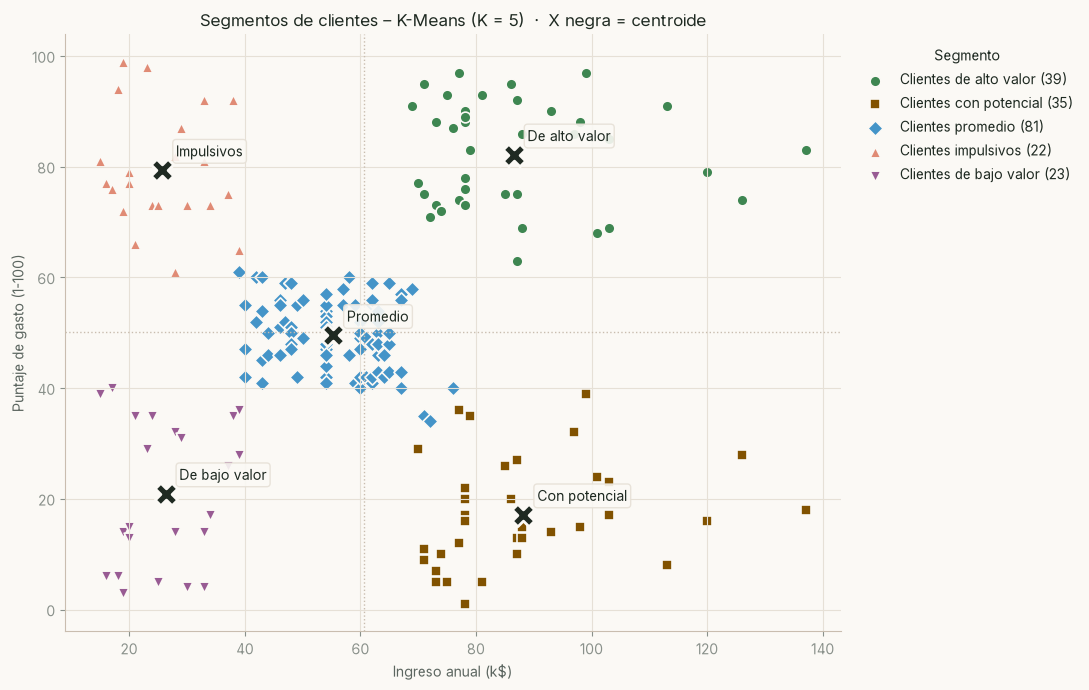

In [22]:
fig, ax = plt.subplots(figsize=(11, 7))
for clave, info in PERFILES.items():
    sub = df[df["Perfil"] == info["nombre"]]
    ax.scatter(sub["Ingreso"], sub["Gasto"], s=60, color=info["color"], marker=info["marcador"],
               edgecolor=SUPERFICIE, linewidth=1.2, label=f"{info['nombre']} ({len(sub)})")
for c, fila in centroides.iterrows():
    ax.scatter(fila["Ingreso"], fila["Gasto"], s=260, marker="X", color=TINTA, edgecolor=SUPERFICIE, linewidth=2, zorder=5)
    ax.annotate(fila["Perfil"].replace("Clientes ", "").capitalize(), (fila["Ingreso"], fila["Gasto"]),
                xytext=(10, 10), textcoords="offset points", fontsize=10, fontweight="bold", color=TINTA,
                bbox={"boxstyle": "round,pad=0.25", "fc": SUPERFICIE, "ec": REJILLA, "alpha": 0.9})
ax.axvline(df["Ingreso"].mean(), color=EJE, lw=1, ls=":")
ax.axhline(df["Gasto"].mean(), color=EJE, lw=1, ls=":")
ax.set_title("Segmentos de clientes – K-Means (K = 5)  ·  X negra = centroide")
ax.set_xlabel("Ingreso anual (k$)"); ax.set_ylabel("Puntaje de gasto (1-100)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), title="Segmento")
mostrar("10_clusters")

**Interpretación – Segmentos obtenidos**
Cada segmento ocupa una región distinta del plano ingreso–gasto. Las líneas punteadas (medias de ingreso y gasto)
dividen el gráfico en cuadrantes:
- **Arriba a la derecha:** alto valor. **Abajo a la derecha:** con potencial. **Arriba a la izquierda:** impulsivos.
  **Abajo a la izquierda:** bajo valor. **Centro:** promedio.
- Los grupos están separados por zonas vacías, excepto en los bordes del grupo promedio, donde están los dos
  clientes con silueta negativa.
- Los grupos de ingreso alto (alto valor y con potencial) son los más **dispersos** horizontalmente (69 a 137 k$). El
  grupo promedio es el más **compacto**.
- Cada X negra (centroide) cae en el centro de su nube, así que representa bien al cliente típico de su grupo.

In [23]:
perfil_clusters = df.groupby("Perfil").agg(
    Clientes=("ID", "size"),
    Edad_media=("Edad", "mean"),
    Ingreso_medio=("Ingreso", "mean"),
    Gasto_medio=("Gasto", "mean"),
    Ingreso_min=("Ingreso", "min"), Ingreso_max=("Ingreso", "max"),
    Gasto_min=("Gasto", "min"), Gasto_max=("Gasto", "max"),
    Pct_mujeres=("Genero", lambda s: (s == "Female").mean() * 100),
).reindex(ORDEN)
perfil_clusters.insert(1, "% del total", perfil_clusters["Clientes"] / len(df) * 100)
perfil_clusters

,Clientes,% del total,Edad_media,Ingreso_medio,Gasto_medio,Ingreso_min,Ingreso_max,Gasto_min,Gasto_max,Pct_mujeres
Perfil,,,,,,,,,,
Clientes de alto valor,39,19.50,32.69,86.54,82.13,69,137,63,97,53.85
Clientes con potencial,35,17.50,41.11,88.20,17.11,70,137,1,39,45.71
Clientes promedio,81,40.50,42.72,55.30,49.52,39,76,34,61,59.26
Clientes impulsivos,22,11.00,25.27,25.73,79.36,15,39,61,99,59.09
Clientes de bajo valor,23,11.50,45.22,26.30,20.91,15,39,3,40,60.87


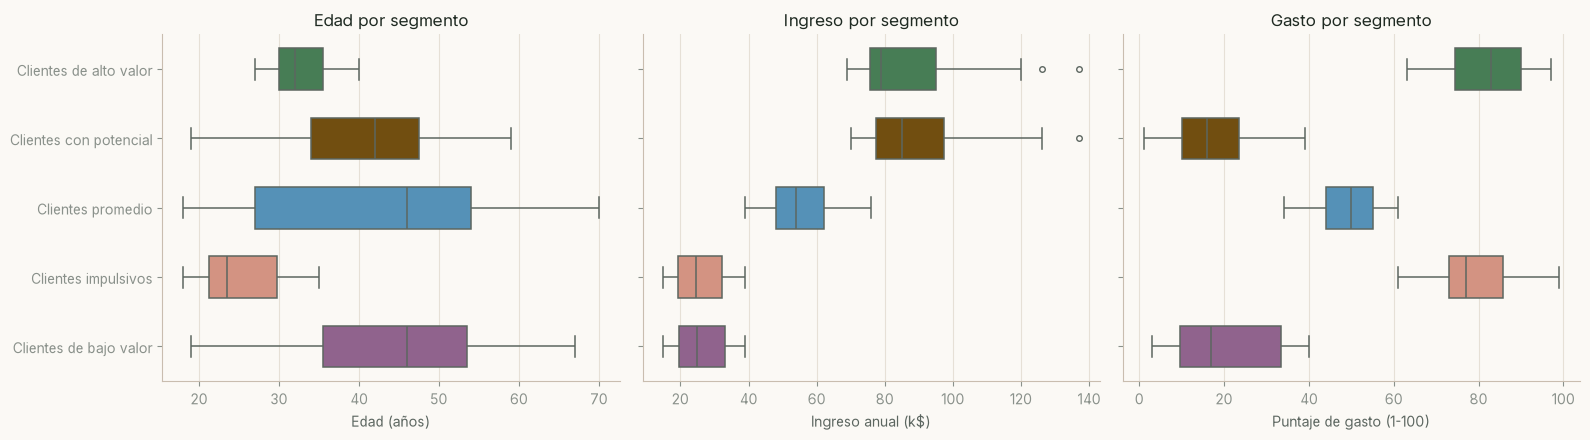

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
colores = [PERFILES[p]["color"] for p in PERFILES]
for ax, col in zip(axes, num):
    sns.boxplot(data=df, y="Perfil", x=col, hue="Perfil", legend=False, order=ORDEN, hue_order=ORDEN, palette=colores, linecolor=TINTA_2,
                linewidth=1.1, width=0.6, fliersize=4, ax=ax)
    ax.set_title(f"{col} por segmento"); ax.set_xlabel(NOMBRES[col]); ax.set_ylabel("")
mostrar("11_perfil_segmentos")

**Interpretación – Variables por segmento**
- **Ingreso** y **Gasto** muestran tres niveles bien separados y con poco cruce entre cajas. Esto confirma que son
  las variables que definen los grupos.
- **Edad** (no se usó en el modelo) muestra diferencias claras: los **impulsivos** (mediana ≈ 24) y los de **alto
  valor** (≈ 32) son jóvenes y con poca variación de edad. Los grupos **promedio** y **bajo valor** abarcan casi todas
  las edades (18–70) y tienen medianas más altas (≈ 46). Los de **con potencial** están en una edad media (≈ 42).
- Para marketing, los segmentos jóvenes son más fáciles de alcanzar por canales digitales. En los grupos de edad
  variada conviene usar canales mixtos.

### Preguntas – Parte 5

**¿Qué representa cada cluster?**

Cada cluster es un grupo de clientes con un **patrón de ingreso y gasto parecido**, y su centroide es el "cliente
típico" del grupo:

| Cluster | Centroide (Ingreso, Gasto) | Clientes | Edad media | Qué representa |
|---|---|---|---|---|
| **Alto valor** | (86.5 k$, 82.1) | 39 (19.5 %) | 32.7 | Ingreso alto y gasto alto. Son los mejores clientes del centro comercial |
| **Con potencial** | (88.2 k$, 17.1) | 35 (17.5 %) | 41.1 | Ingreso alto pero gasto muy bajo. Tienen dinero y no lo gastan aquí |
| **Promedio** | (55.3 k$, 49.5) | 81 (40.5 %) | 42.7 | Ingreso y gasto medios. Es el grupo más grande |
| **Impulsivos** | (25.7 k$, 79.4) | 22 (11.0 %) | 25.3 | Ingreso bajo pero gasto alto. Jóvenes que compran mucho en proporción a lo que ganan |
| **Bajo valor** | (26.3 k$, 20.9) | 23 (11.5 %) | 45.2 | Ingreso bajo y gasto bajo. Compran poco y solo lo necesario |

**¿Qué diferencias existen entre los grupos obtenidos?**

1. **Ingreso:** los grupos se dividen en tres niveles bien marcados: bajo (≈ 26 k$: impulsivos y bajo valor), medio
   (≈ 55 k$: promedio) y alto (≈ 87 k$: alto valor y con potencial). Los rangos casi no se cruzan.
2. **Gasto:** dentro de cada nivel de ingreso extremo hay dos comportamientos opuestos. Hay clientes que gastan
   mucho (≈ 80) y clientes que gastan muy poco (≈ 17–21). Con el mismo dinero, **la actitud de compra cambia
   por completo**.
3. **Edad (variable que no se usó para entrenar):** los segmentos que más gastan son los más **jóvenes**
   (impulsivos 25 años y alto valor 33 años). Los que menos gastan son **mayores** (con potencial 41 y bajo valor 45).
   Esto confirma la correlación negativa edad–gasto de la Parte 1.
4. **Género:** la proporción de mujeres varía poco entre grupos (46 %–61 %), así que no define los segmentos.
5. **Tamaño:** el grupo promedio reúne al 40 % de los clientes. Los otros cuatro tienen entre 11 % y 20 % cada uno.

---
# Parte 6 – Interpretación de negocio

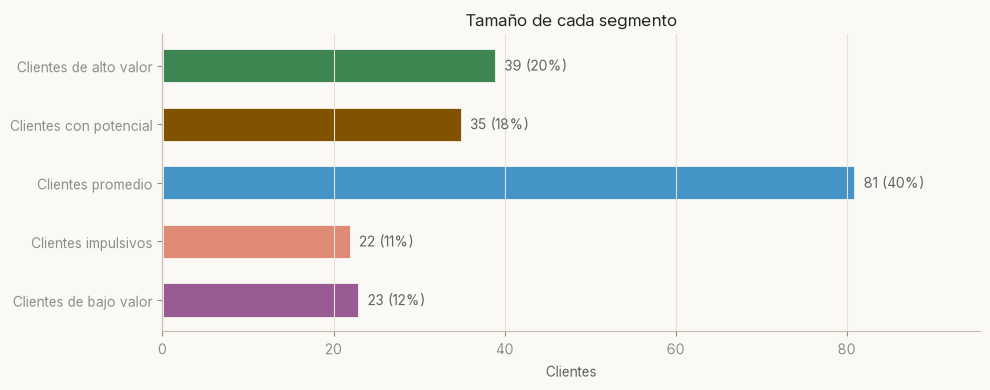

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
tam = perfil_clusters["Clientes"]
barras = ax.barh(ORDEN[::-1], tam[ORDEN[::-1]], color=[PERFILES[p]["color"] for p in list(PERFILES)[::-1]],
                 height=0.6, edgecolor=SUPERFICIE, linewidth=2)
for b, v in zip(barras, tam[ORDEN[::-1]]):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f"{v} ({v / len(df):.0%})", va="center", color=TINTA_2)
ax.set_title("Tamaño de cada segmento"); ax.set_xlabel("Clientes"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, tam.max() * 1.18)
mostrar("12_tamano_segmentos")

**Interpretación – Tamaño de los segmentos**
El grupo **promedio** es el más numeroso (81 clientes, 40.5 %), casi el doble que cualquier otro. Los dos segmentos de
ingreso alto suman **74 clientes (37 %)**: 39 ya son de alto valor y 35 tienen potencial sin aprovechar. Los
segmentos de ingreso bajo (impulsivos y bajo valor) son los más pequeños (11 % cada uno).

### Clasificación de los clusters en perfiles

| Perfil | Ingreso | Gasto | Edad | % | Descripción |
|---|---|---|---|---|---|
| **Clientes de alto valor** | Alto (86.5 k$) | Alto (82) | 33 | 19.5 % | Los clientes más rentables. Compran seguido y gastan mucho |
| **Clientes con potencial** | Alto (88.2 k$) | Bajo (17) | 41 | 17.5 % | Tienen alto poder adquisitivo pero casi no compran. Es dinero que está quedando sin aprovechar |
| **Clientes promedio** | Medio (55.3 k$) | Medio (50) | 43 | 40.5 % | La base estable del negocio. Compran de forma moderada |
| **Clientes impulsivos** | Bajo (25.7 k$) | Alto (79) | 25 | 11.0 % | Jóvenes muy activos y sensibles a tendencias, pero con poco presupuesto |
| **Clientes de bajo valor** | Bajo (26.3 k$) | Bajo (21) | 45 | 11.5 % | Poco poder adquisitivo y poca intención de compra |

Los cuatro perfiles del enunciado (alto valor, promedio, bajo valor y con potencial) aparecen claramente. El quinto
grupo, los **impulsivos**, surge porque K = 5 es el óptimo: tienen un comportamiento propio (gastan mucho con
ingresos bajos) que no encaja en los otros cuatro.

### Preguntas – Parte 6

**¿Qué estrategias de marketing se podrían aplicar a cada grupo?**

| Segmento | Objetivo | Estrategias |
|---|---|---|
| **Alto valor** | **Retener y fidelizar** | Programa VIP o de lealtad con beneficios exclusivos (acceso anticipado a colecciones, eventos privados, parqueadero preferencial). Atención personalizada con *personal shopper*. Venta de productos premium y de marcas exclusivas. Monitorear señales de abandono, porque perder a uno de estos clientes cuesta mucho |
| **Con potencial** | **Activar y convertir** | Entender por qué no compran (encuestas, análisis de qué tiendas visitan). Propuestas de calidad, exclusividad y ahorro de tiempo más que descuentos: servicios premium, experiencias, gastronomía, tecnología, artículos para el hogar. Comunicación por canales profesionales (email, LinkedIn). Campañas de "bienvenida" o "redescubre el centro comercial" con incentivos atados al primer gasto alto |
| **Promedio** | **Aumentar el ticket y la frecuencia** | Venta cruzada y combos. Programa de puntos que premie la frecuencia. Promociones de temporada (regreso a clases, fechas especiales). Notificaciones por app. Al ser el 40 % de la base, pequeñas mejoras generan mucho volumen |
| **Impulsivos** | **Mantener la actividad de forma sostenible** | Marketing en redes sociales e *influencers*, *flash sales*, tendencias y novedades. Opciones de pago en cuotas o "compra ahora y paga después" con responsabilidad. Gamificación y recompensas. Programas de lealtad para que sigan como clientes cuando aumenten sus ingresos y pasen a alto valor |
| **Bajo valor** | **Atender con baja inversión** | Comunicación masiva de bajo costo. Promociones de precio, *outlets* y días de descuento. Productos esenciales y marcas propias. No dedicar mucho presupuesto de marketing personalizado a este grupo |

**¿Qué segmento representa mayor oportunidad de crecimiento?**

Los **clientes con potencial** (ingreso alto y gasto bajo).

1. **Tienen la capacidad de pago más alta de todos** (88.2 k$ en promedio, incluso más que el grupo de alto valor),
   pero su puntaje de gasto es el más bajo (17.1). La diferencia entre lo que *pueden* gastar y lo que *gastan* es
   la más grande de todos los segmentos.
2. **Son un grupo grande:** 35 clientes, el 17.5 % de la base, casi el mismo tamaño que el grupo de alto valor.
3. **Es un cálculo sencillo:** si este grupo subiera su gasto solo hasta el nivel del grupo promedio (≈ 50), su
   puntaje de gasto **casi se triplicaría**, sin necesidad de conseguir clientes nuevos.
4. Ya visitan el centro comercial (están registrados). Lo que hay que resolver es **por qué no compran**, lo cual es
   más barato que atraer clientes desde cero.

En segundo lugar están los **clientes promedio**: por su tamaño (40 %), cualquier aumento en su gasto se nota mucho
en los ingresos totales. Los **impulsivos** son una oportunidad a **largo plazo**, porque son jóvenes y
probablemente sus ingresos van a crecer.

---
# Parte 7 – Exportación del modelo para el despliegue
Se guardan en un solo archivo el escalador, el modelo K-Means y el mapa de perfiles. La aplicación de Streamlit
(`app.py`) carga este archivo para clasificar clientes nuevos con **exactamente** el mismo preprocesamiento.

In [26]:
Path("modelo").mkdir(exist_ok=True)
paquete = {
    "scaler": scaler,
    "kmeans": kmeans,
    "features": FEATURES,
    "mapa_perfil": MAPA_PERFIL,
    "perfiles": PERFILES,
    "metricas": {"silueta": float(silhouette_score(X_esc, df["Cluster"])),
                 "davies_bouldin": float(davies_bouldin_score(X_esc, df["Cluster"])),
                 "inercia": float(kmeans.inertia_)},
}
joblib.dump(paquete, "modelo/kmeans_clientes.joblib")
print("Modelo guardado en modelo/kmeans_clientes.joblib")

Modelo guardado en modelo/kmeans_clientes.joblib


#### Prueba: clasificar clientes nuevos con el modelo guardado

In [27]:
modelo = joblib.load("modelo/kmeans_clientes.joblib")

def clasificar(ingreso, gasto):
    x = modelo["scaler"].transform(pd.DataFrame([[ingreso, gasto]], columns=modelo["features"]))
    c = int(modelo["kmeans"].predict(x)[0])
    return modelo["perfiles"][modelo["mapa_perfil"][c]]["nombre"]

nuevos = pd.DataFrame({"Ingreso": [120, 90, 20, 55, 18], "Gasto": [90, 10, 85, 45, 12]})
nuevos["Perfil asignado"] = [clasificar(i, g) for i, g in zip(nuevos["Ingreso"], nuevos["Gasto"])]
nuevos

,Ingreso,Gasto,Perfil asignado
0,120,90,Clientes de alto valor
1,90,10,Clientes con potencial
2,20,85,Clientes impulsivos
3,55,45,Clientes promedio
4,18,12,Clientes de bajo valor


---
# Conclusiones

1. **Variables:** Ingreso anual y puntaje de gasto son las mejores variables para segmentar. No están correlacionadas,
   se interpretan fácilmente y muestran cinco grupos naturales. Agregar la edad empeora la silueta (0.555 → 0.427).
2. **Preprocesamiento:** el dataset no tiene nulos ni duplicados. Los 2 valores atípicos de ingreso son legítimos y se
   conservan. La estandarización evita que una variable domine la distancia euclidiana.
3. **Número de clusters:** el método del codo, el coeficiente de silueta (0.555) y el índice Davies-Bouldin (0.572)
   coinciden en **K = 5**. El modelo es estable (ARI ≈ 1 entre semillas).
4. **Segmentos:** alto valor (19.5 %), con potencial (17.5 %), promedio (40.5 %), impulsivos (11 %) y bajo valor (11.5 %).
5. **Negocio:** la mayor oportunidad de crecimiento son los **clientes con potencial**: tienen ingreso alto y gasto bajo.
   La prioridad para proteger los ingresos actuales es **retener a los clientes de alto valor**.
6. **Despliegue:** el modelo se exportó y se usa en una aplicación de Streamlit que muestra el método del codo y los
   clusters, y clasifica clientes nuevos en tiempo real.